In [1]:
%pylab inline
import os
import gc
import numpy as np
import astropy.io.fits as pyfits
from astropy.table import Table,vstack
import sim_analysis_utilities as utilities
import pandas as pd

import matplotlib as mpl
mpl.rcParams['savefig.dpi'] = 'figure'
mpl.rcParams['savefig.jpeg_quality'] = 100
matplotlib.rcParams['font.size'] = 14

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.ticker as mtick
import matplotlib.lines as mlines
from matplotlib.colors import LogNorm

Populating the interactive namespace from numpy and matplotlib


In [2]:
anaDir     =   './wrkDir/s19/s19-1/anaCat_newS19Mask/'
simAname=   os.path.join(anaDir,'allSim.h5')
sims    =   pd.read_hdf(simAname,mode='r').to_records(index=True)
maskS   =   (sims['logb']<=-0.375)
maskS   &=  (sims['res']>0.3)
maskS   &=  (sims['snr']>10.)
maskS   &=  (sims['absE']<2.)
maskS   &=  ((sims['mag']-sims['a_i'])<24.5)
maskS   &=  (sims['magA10']<25.5)
sims    =   sims[maskS]
weight_sims =   sims['weight']

/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:9: RuntimeWarning: invalid value encountered in less
  if __name__ == '__main__':


In [28]:
Dir='./wrkDir/s19/s19-1/.catalog_obs_reGaus_calibrated/fields/'
snr=[]
mag=[]
res=[]
absE=[]
for ii,fieldname in enumerate(utilities.field_names):
    # observation
    inFname =   os.path.join(Dir,'%s_calibrated.fits' %(fieldname))
    data    =   pyfits.getdata(inFname)
    absE.append(utilities.get_abs_ellip(data))
    res.append(utilities.get_res(data))
    mag.append(utilities.get_imag(data))
    snr.append(utilities.get_snr(data))
    del data
    gc.collect()
snr=np.hstack(snr)
mag=np.hstack(mag)
res=np.hstack(res)
absE=np.hstack(absE)
gc.collect()

0

In [ ]:
if False:
    del fig
fig,axes = plt.subplots(1,3,figsize=(15, 5),constrained_layout=True)

"""
# The First Panel
"""
ax = axes[0]
counts1= np.histogram2d(snr, res, 32, range=[[10,80],[0.3,1]], normed=True)[0]
ax.contour(counts1.T,extent=[10,80,0.3,1],cmap='viridis', levels=[0.01, 0.025, 0.05, 0.075])
ax.hist2d(snr, res, 128, range=[[10,80],[0.3,1]], cmap='gray_r', normed=True,vmax=0.08,alpha=0.8);

counts2= np.histogram2d(sims['snr'], sims['res'], 32, weights=weight_sims, range=[[10,80],[0.3,1]], normed=True)[0]
ax.contour(counts2.T,extent=[10,80,0.3,1],cmap='viridis',linestyles='dashed', levels=[0.01, 0.025, 0.05, 0.075])
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
ax.set_xlabel('CModel SNR')
ax.set_ylabel('reGaus resolution')
#ax.set_xscale('log')

In [34]:
"""
# The Second Panel
"""
ax = axes[1]
counts1= np.histogram2d(snr, absE, 32, range=[[10,80],[0.,2]], normed=True)[0]
ax.contour(counts1.T,extent=[10,80,0.,2],cmap='viridis', levels=[0.0065, 0.012, 0.025, 0.035])
ax.hist2d(snr, absE,128, range=[[10,80],[0.,2]], cmap='gray_r', normed=True,alpha=0.8,norm=LogNorm(vmin=0.0002,vmax=0.2));

counts2= np.histogram2d(sims['snr'], sims['absE'], 32, weights=weight_sims, range=[[10,80],[0.,2]], normed=True)[0]
ax.contour(counts2.T,extent=[10,80,0.,2], cmap='viridis', linestyles='dashed', levels=[0.0065,0.012,0.025,0.035])
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
ax.set_xlabel('CModel SNR')
ax.set_ylabel(r'reGaus $|e|$')
#ax.set_xscale('log')

"""
#  Adding legend
"""
data_line = mlines.Line2D([], [], color='black', ls='-', label='Data')
sims_line = mlines.Line2D([], [], color='black', ls='--',label='Simulation')
ax.legend(handles=[data_line,sims_line])

In [35]:
"""
# The third panel
"""
ax = axes[2]
counts1,xbins1,ybins1,image = ax.hist2d(snr, mag, 32, range=[[10,80],[22,24.5]], cmap='gray_r', normed=True,vmax=0.1);
ax.contour(counts1.T,extent=[10,80,22,24.5],cmap='viridis', levels=[0.01, 0.025, 0.05, 0.075])
ax.hist2d(snr, mag, 128, range=[[10,80],[22,24.5]], cmap='gray_r', normed=True,vmax=0.1,alpha=0.8,norm=LogNorm(vmin=0.005,vmax=0.1));

counts2,xbins2,ybins2,image = ax.hist2d(sims['snr'], sims['mag'], 32, weights=weight_sims, range=[[10,80],[22,24.5]], cmap='gray_r', normed=True,vmax=0.1);
ax.contour(counts2.T,extent=[10,80,22,24.5], cmap='viridis', linestyles='dashed', levels=[0.01,0.025,0.05,0.075])
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
ax.set_xlabel('CModel SNR')
ax.set_ylabel('CModel mag')
ax.set_ylim(24.5,22)
#ax.set_xscale('log')

(24.5, 22)

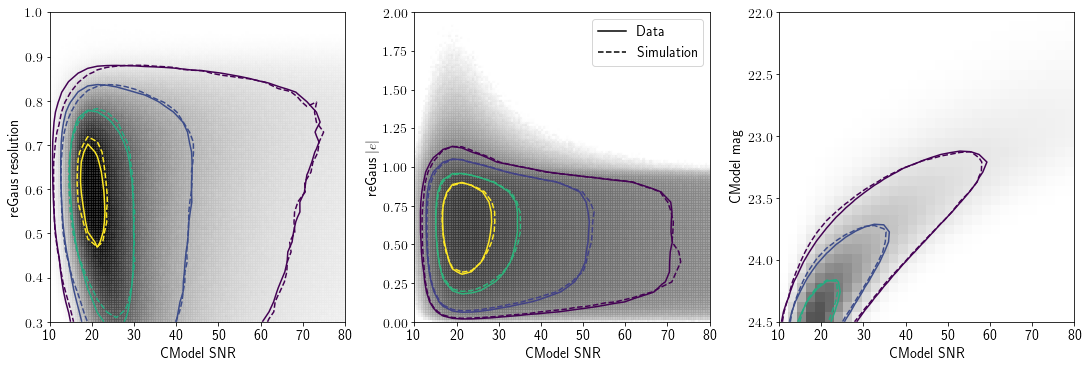

In [36]:
fig

In [37]:
"""
# Save figure
"""
pltDir  =   'wrkDir/s19/s19-1/plot/galDis2D/'
fig.savefig(os.path.join(pltDir,'galDis2D-final_reCheck.eps' ))
fig.savefig(os.path.join(pltDir,'galDis2D-final_reCheck.png' ))

In [40]:
for ii,fieldname in enumerate(utilities.field_names):
    # observation
    inFname =   os.path.join(Dir,'%s_calibrated.fits' %(fieldname))
    data    =   pyfits.getdata(inFname)
    mask0   =   data['weak_lensing_flag']
    mask=utilities.update_wl_flags(data)['weak_lensing_flag']
    print(np.all(mask0==mask))
    del data
    gc.collect()

True
True
True
True
True
True


In [41]:
for ii,fieldname in enumerate(utilities.field_names):
    # observation
    inFname =   os.path.join(Dir,'%s_calibrated.fits' %(fieldname))
    data    =   pyfits.getdata(inFname)
    mask0   =   data['weak_lensing_flag']
    print(np.all(mask0))
    del data
    gc.collect()

True
True
True
True
True
True
